In [1]:
%load_ext pyspecdata.ipy
from itertools import cycle
import matplotlib.pyplot as plt
import numpy as np

First, we load our files, and just see what the data looks like

In [32]:
#  w0 = 3 
d1 = find_file("240226_CAT16_C10_W3_run1.DSC", exp_type="francklab_esr/romana") # cooling 1 --initial sample
d2 = find_file("240226_CAT16_C10_W3_run2.DSC", exp_type="francklab_esr/romana") # heating 2 subsequently --after cooling and heating

# w0 = 20
d3 = find_file("240226_CAT16_C10_W20_run1.DSC", exp_type="francklab_esr/romana") # cooling 1 --initial sample
d4 = find_file("240226_CAT16_C10_W20_run2.DSC", exp_type="francklab_esr/romana") # heating 2 subsequently --after cooling and heating

In [33]:
d1.shape  # this shows me what the dimensions are

[(1024, '$B_0$'), (13, 'Temperature'), (10, 'harmonic')]

In [34]:
d2.shape

[(1024, '$B_0$'), (13, 'Temperature'), (10, 'harmonic')]

In [35]:
d3.shape

[(1024, '$B_0$'), (13, 'Temperature'), (10, 'harmonic')]

In [36]:
d4.shape

[(1024, '$B_0$'), (13, 'Temperature'), (10, 'harmonic')]

In [37]:
d1.chunk_auto("harmonic", "harmonic")  # the harmonic is typically stored so that we need to do this
d1.shape  # this shows me what the dimensions are

[(1024, '$B_0$'), (13, 'Temperature'), (2, 'phase'), (5, 'harmonic')]

In [38]:
d2.chunk_auto("harmonic", "harmonic")
d2.shape

[(1024, '$B_0$'), (13, 'Temperature'), (2, 'phase'), (5, 'harmonic')]

In [39]:
d3.chunk_auto
d3.shape

[(1024, '$B_0$'), (13, 'Temperature'), (10, 'harmonic')]

In [40]:
d4.chunk_auto
d4.shape

[(1024, '$B_0$'), (13, 'Temperature'), (10, 'harmonic')]

I start by plotting as a 2D pcolor plot:

Text(0.5, 1.0, 'CAT16 w$_0= 3$ in Dodecane for cooling')

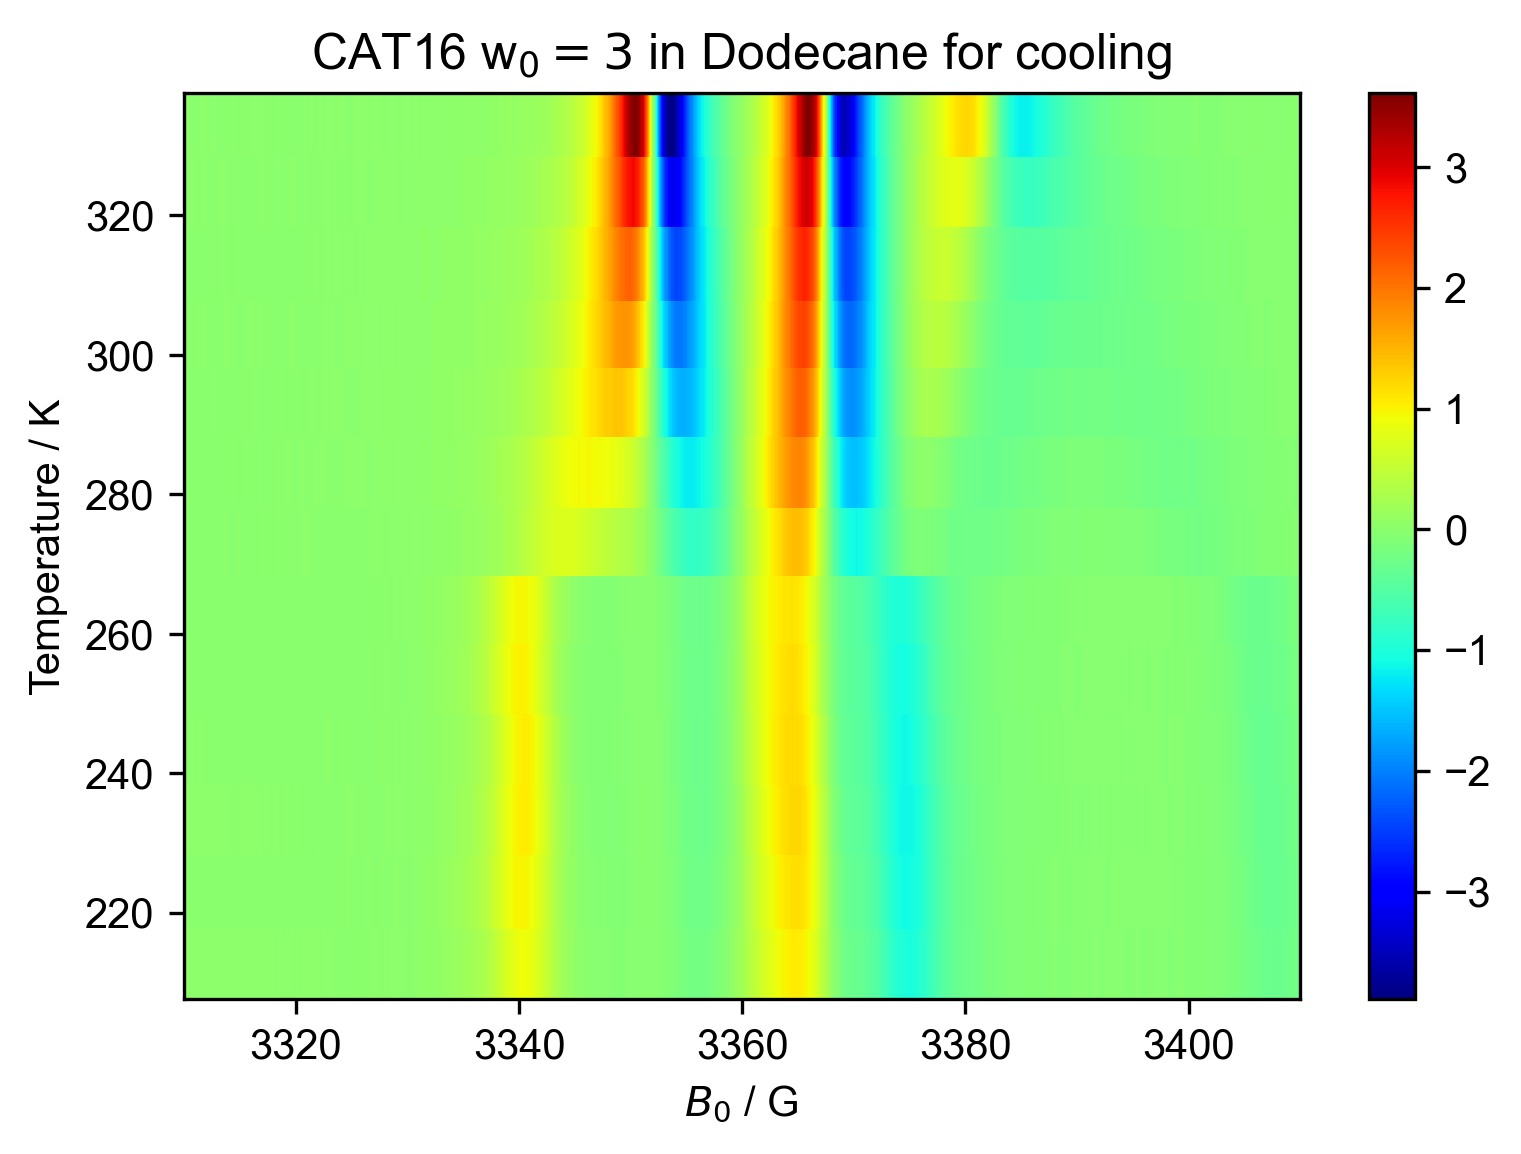

In [41]:
# w0 = 3 cooling
figure(dpi=300)
d1 = d1["harmonic", 0]["phase", 0]  # select only the "standard" EPR -- ignore the higher harmonics.  Make sure you can parse this!
d1.sort('Temperature')
# d1.pcolor()
d1.reorder("Temperature").pcolor()
title("CAT16 w$_0= 3$ in Dodecane for cooling")

Text(0.5, 1.0, 'CAT16 w$_0= 3$ in Dodecane for heating')

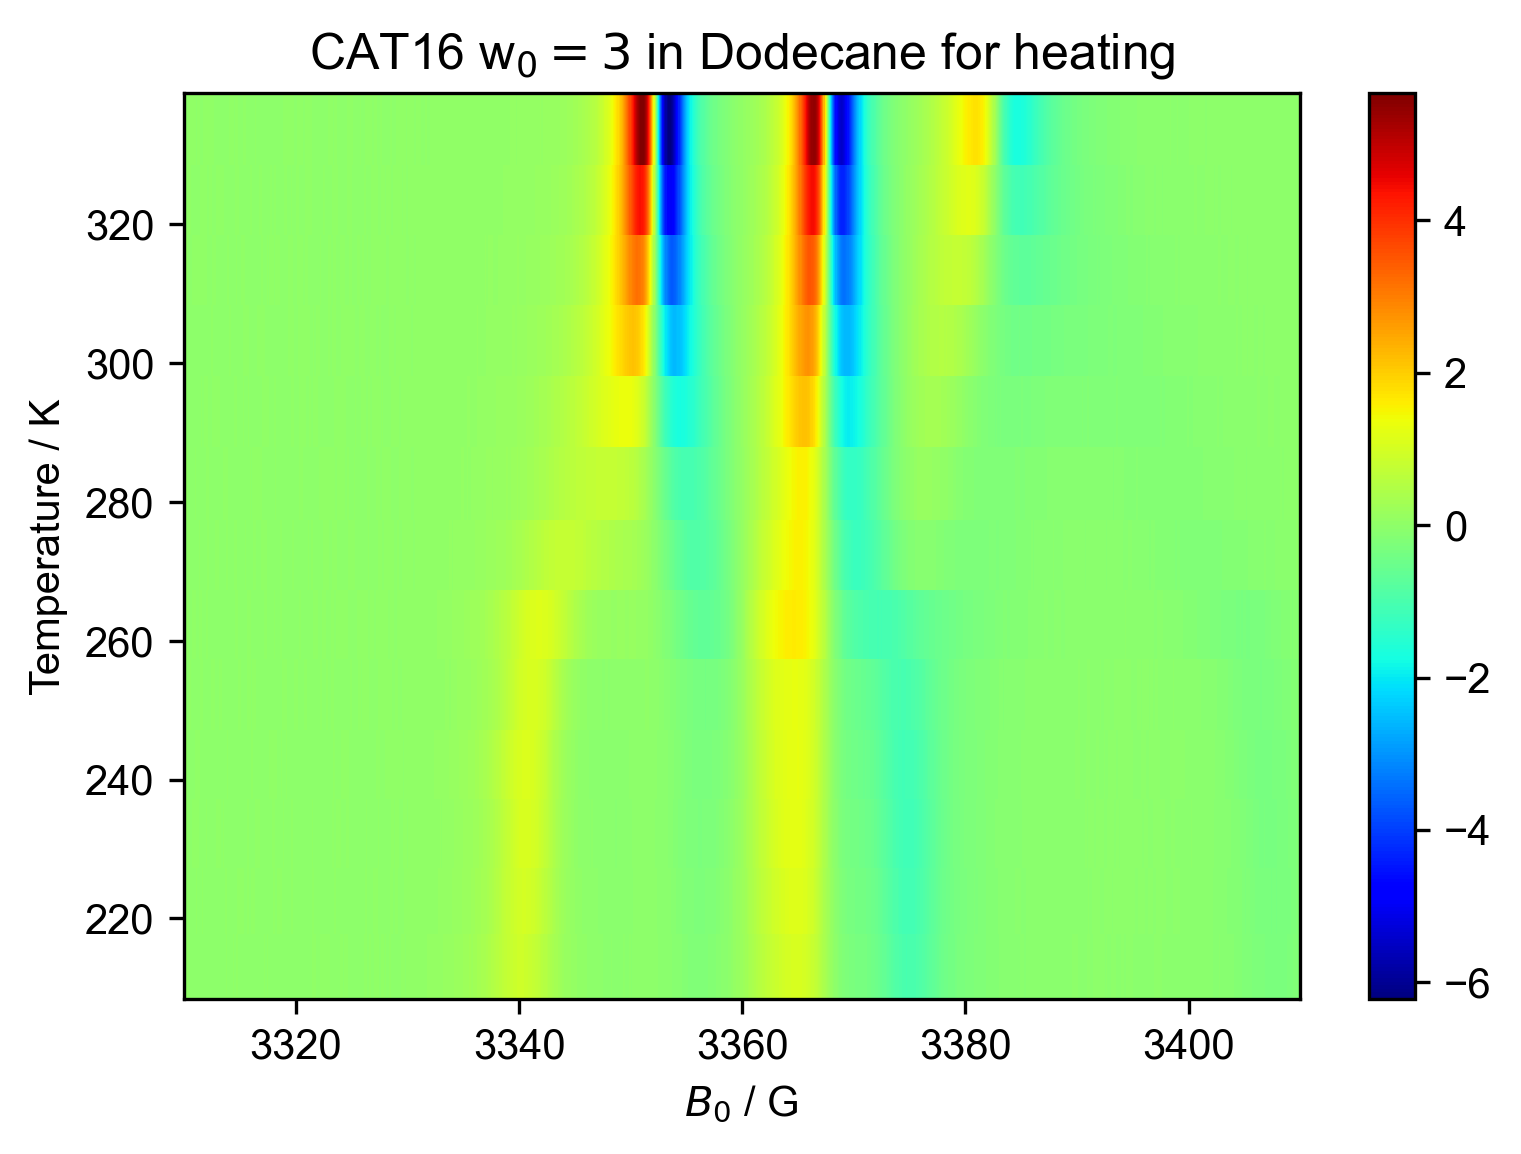

In [42]:
# w0 = 3 heating
figure(dpi=300)
d2 = d2["harmonic", 0]["phase", 0]
d2.sort('Temperature')
# d2.pcolor()
d2.reorder("Temperature").pcolor()
title("CAT16 w$_0= 3$ in Dodecane for heating")

In [44]:
# # w0 = 20 cooling 
# figure(dpi=300)
# d3 = d3["harmonic", 0]["phase", 0]  # select only the "standard" EPR -- ignore the higher harmonics.  Make sure you can parse this!
# d3.sort('Temperature')
# # d3.pcolor()
# d3.reorder("Temperature").pcolor()
# title("CAT16 w$_0= 20$ in Dodecane for cooling")

In [45]:
# # w0 = 20 heating
# figure(dpi=300)
# d4 = d4["harmonic", 0]["phase", 0]
# d4.sort('Temperature')
# # d4.pcolor()
# d4.reorder("Temperature").pcolor()
# title("CAT16 w$_0= 20$ in Dodecane for heating")

From this, I learn that
it's easiest to show the 1D plots above and below the transition

In [9]:
# #cooling
# for this_label, temp_range in [
#     ("below transition", (None, 257.8)),
#     ("above transition", (258, None)),
# ]:
#     this_d1 = d1["Temperature":temp_range]
#     figure(dpi=300) # this is standard matplotlib to open a new figure
#     title(this_label)
#     for temp_ithis_dx in range(this_d1.shape["Temperature"]):
#         this_temp = this_d1.getaxis("Temperature")[temp_ithis_dx]
#         plot(this_d1["Temperature", temp_ithis_dx], label=f"{this_temp} K")
#     fancy_legend()

In [10]:
# #cooling same plot
# for this_label, temp_range in [
#     ("All transition", (173, 373))
#  #   ("above transition", (258, None)),
# ]:
#     this_d1 = d1["Temperature":temp_range]
#     figure(dpi=300) # this is standard matplotlib to open a new figure
#     title(this_label)
#     for temp_ithis_dx in range(this_d1.shape["Temperature"]):
#         this_temp = this_d1.getaxis("Temperature")[temp_ithis_dx]
#         plot(this_d1["Temperature", temp_ithis_dx], label=f"{this_temp} K")
#     fancy_legend()

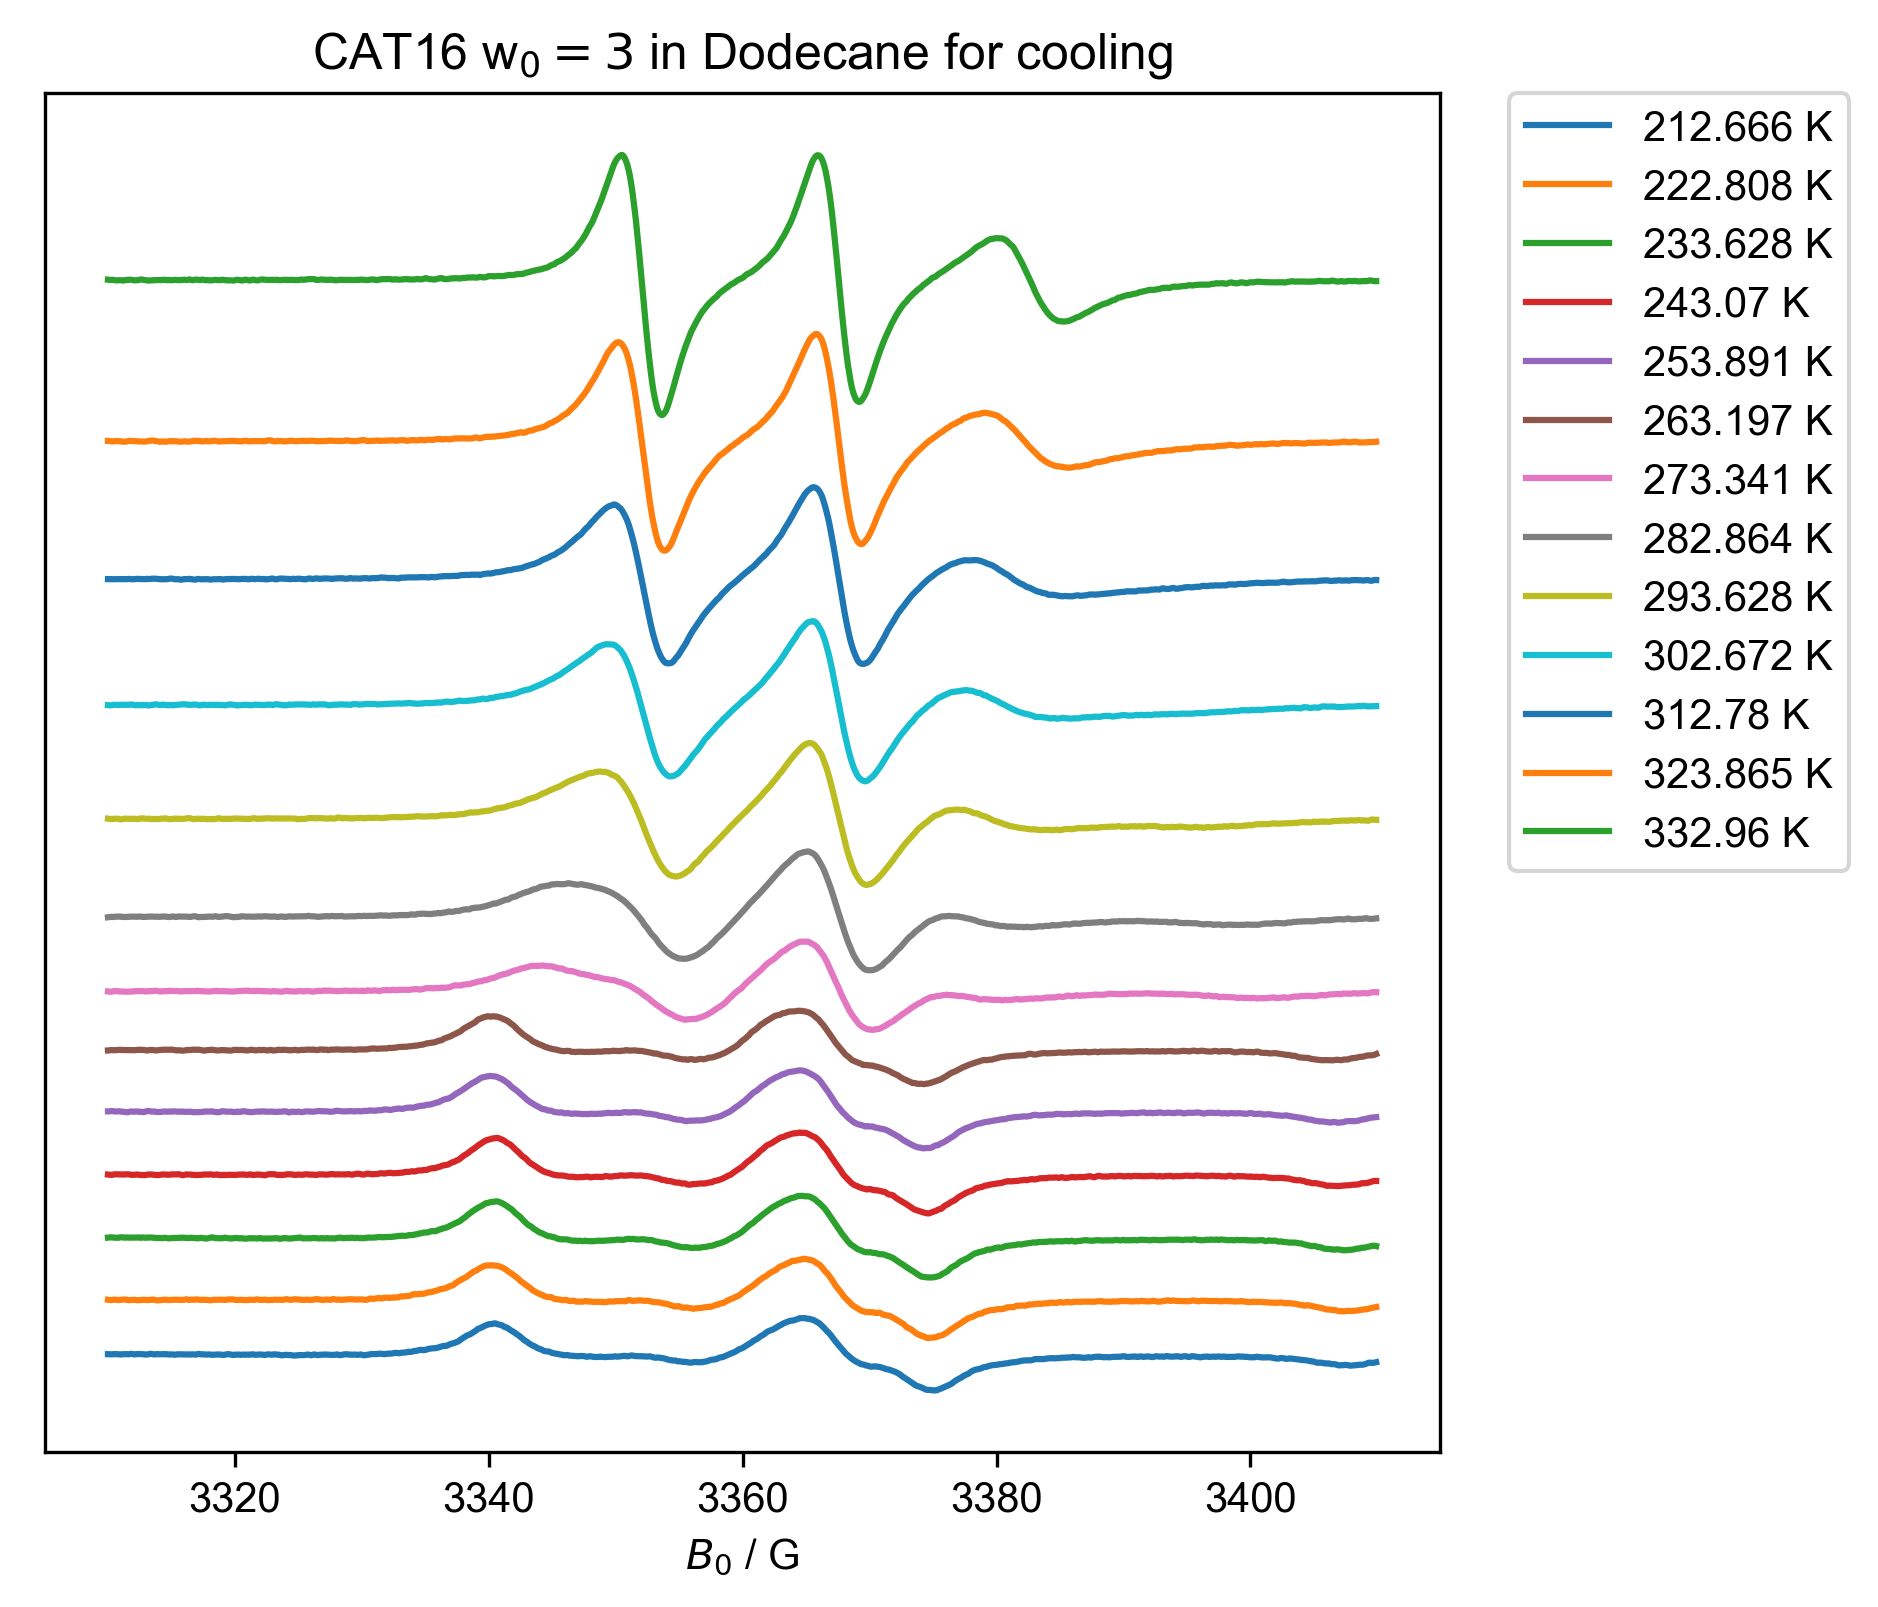

In [25]:
#cooling same plot in offset
offset= 0

for this_label, temp_range in [
    ("CAT16 w$_0= 3$ in Dodecane for cooling", (173, 373))
]:
    this_d1 = d1["Temperature":temp_range]
    figure(dpi=300, figsize=(6,6)) # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d1.shape["Temperature"]):
        this_temp = this_d1.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d1["Temperature", temp_ithis_dx] + offset, label=f"{this_temp} K")        
        offset += this_d1["Temperature", temp_ithis_dx].max()*1.5
        ax=plt.gca()
        ax.set_yticks([])
        ax.set_ylabel(None)
    fancy_legend()

In [12]:
#cooling same plot in offset --legend reorder
# offset= 0

# for this_label, temp_range in [
#     ("TEMPO-SO$_4$ w$_0= 3$ in isooctane for cooling", (173, 373))
#  #   ("above transition", (258, None)),
# ]:
#     this_d1 = d1["Temperature":temp_range]
#     figure(dpi=300, figsize=(6,6)) # this is standard matplotlib to open a new figure
#     title(this_label)
#     for temp_ithis_dx in range(this_d1.shape["Temperature"]):
#         this_temp = this_d1.getaxis("Temperature")[temp_ithis_dx]
#         plot(this_d1["Temperature", temp_ithis_dx] + offset, label=f"{this_temp} K")        
#         offset += this_d1["Temperature", temp_ithis_dx].max()*1.5
#         ax=plt.gca()
#         ax.set_yticks([])
#         ax.set_ylabel(None)
# #         handles, labels = plt.gca().get_legend_handles_labels()
# #         order = [1, 0]  # Specify the desired order of legend entries
# #         plt.legend([handles[temp_ithis_dx] for temp_ithis_dx in order], [labels[temp_ithis_dx] for temp_ithis_dx in order])

#         handles, labels = ax.get_legend_handles_labels()
#         order = [1, 0]
# #         fancy_legend(ax())
# #         ax.legend(handles[::-1], labels[::-1])
#         #legend.reorder()
#     fancy_legend(ax.legend(handles[::-1], labels[::-1]))
# #     fancy_legend()
        

In [13]:
# #heating run2
# for this_label, temp_range in [
#     ("below transition", (None, 247.8)),
#     ("above transition", (248, None)),
# ]:
#     this_d2 = d2["Temperature":temp_range]
#     figure() # this is standard matplotlib to open a new figure
#     title(this_label)
#     for temp_ithis_dx in range(this_d2.shape["Temperature"]):
#         this_temp = this_d2.getaxis("Temperature")[temp_ithis_dx]
#         plot(this_d2["Temperature", temp_ithis_dx], label=f"{this_temp} K")
#     fancy_legend()

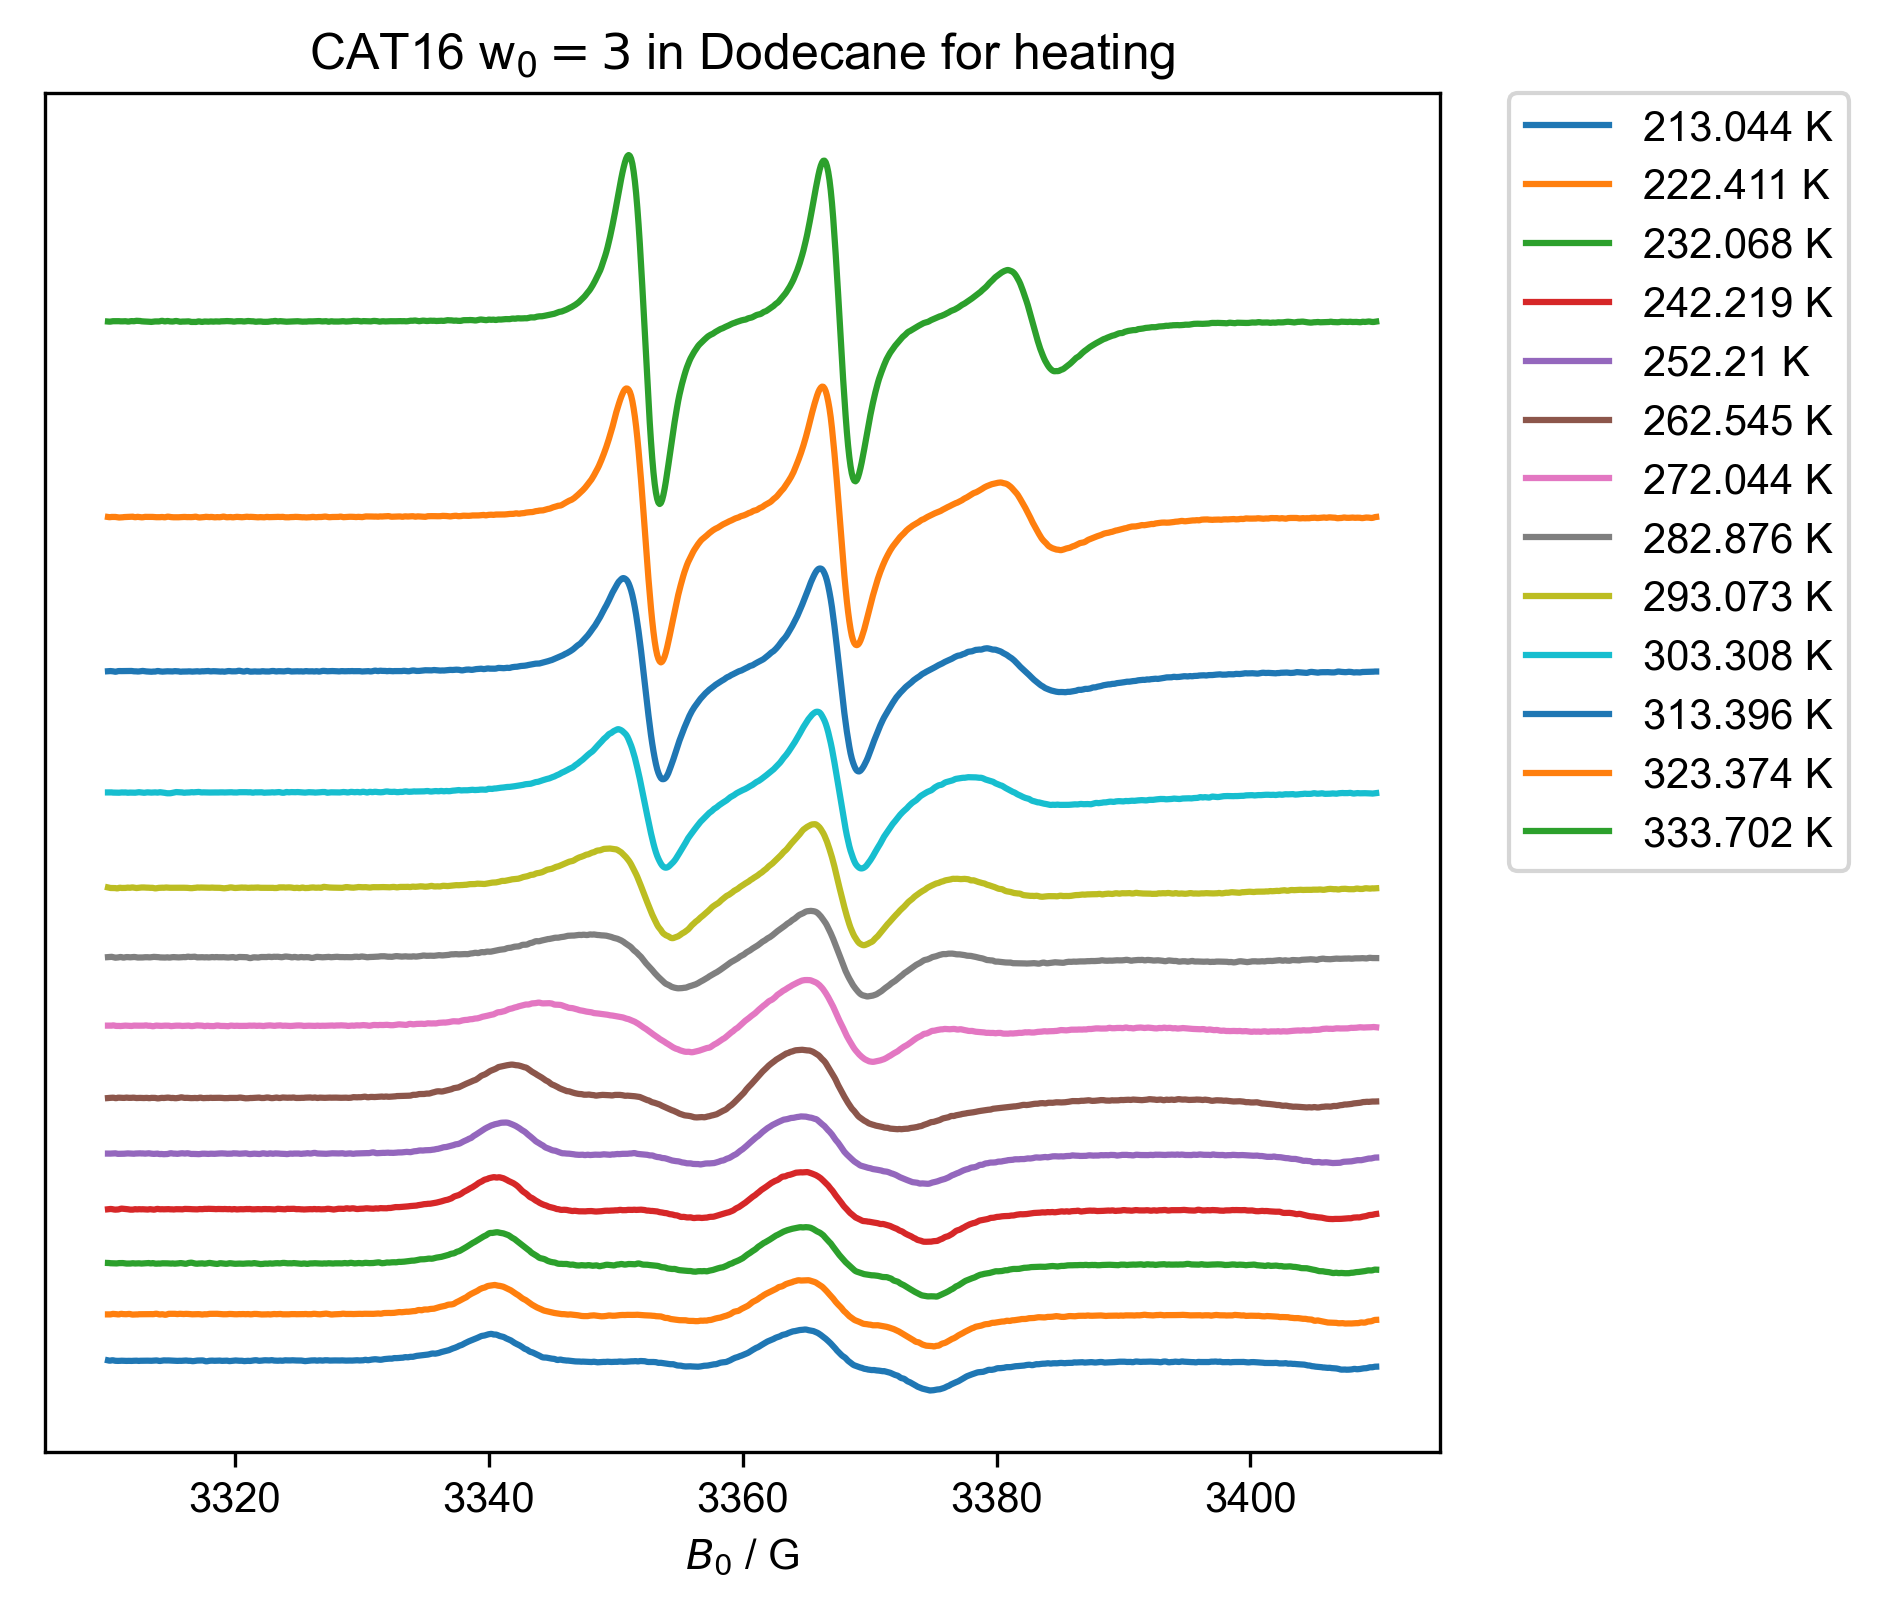

In [26]:
#heating run2 in same plot
offset =0

for this_label, temp_range in [
    ("CAT16 w$_0=3$ in Dodecane for heating", (173, 373)),
]:
    this_d2 = d2["Temperature":temp_range]
    figure(dpi=300, figsize=(6,6)) # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d2.shape["Temperature"]):
        this_temp = this_d2.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d2["Temperature", temp_ithis_dx] + offset, label=f"{this_temp} K")
        offset += this_d2["Temperature", temp_ithis_dx].max()*1.5
        ax=plt.gca()
        ax.set_yticks([])
        ax.set_ylabel(None)
    fancy_legend()

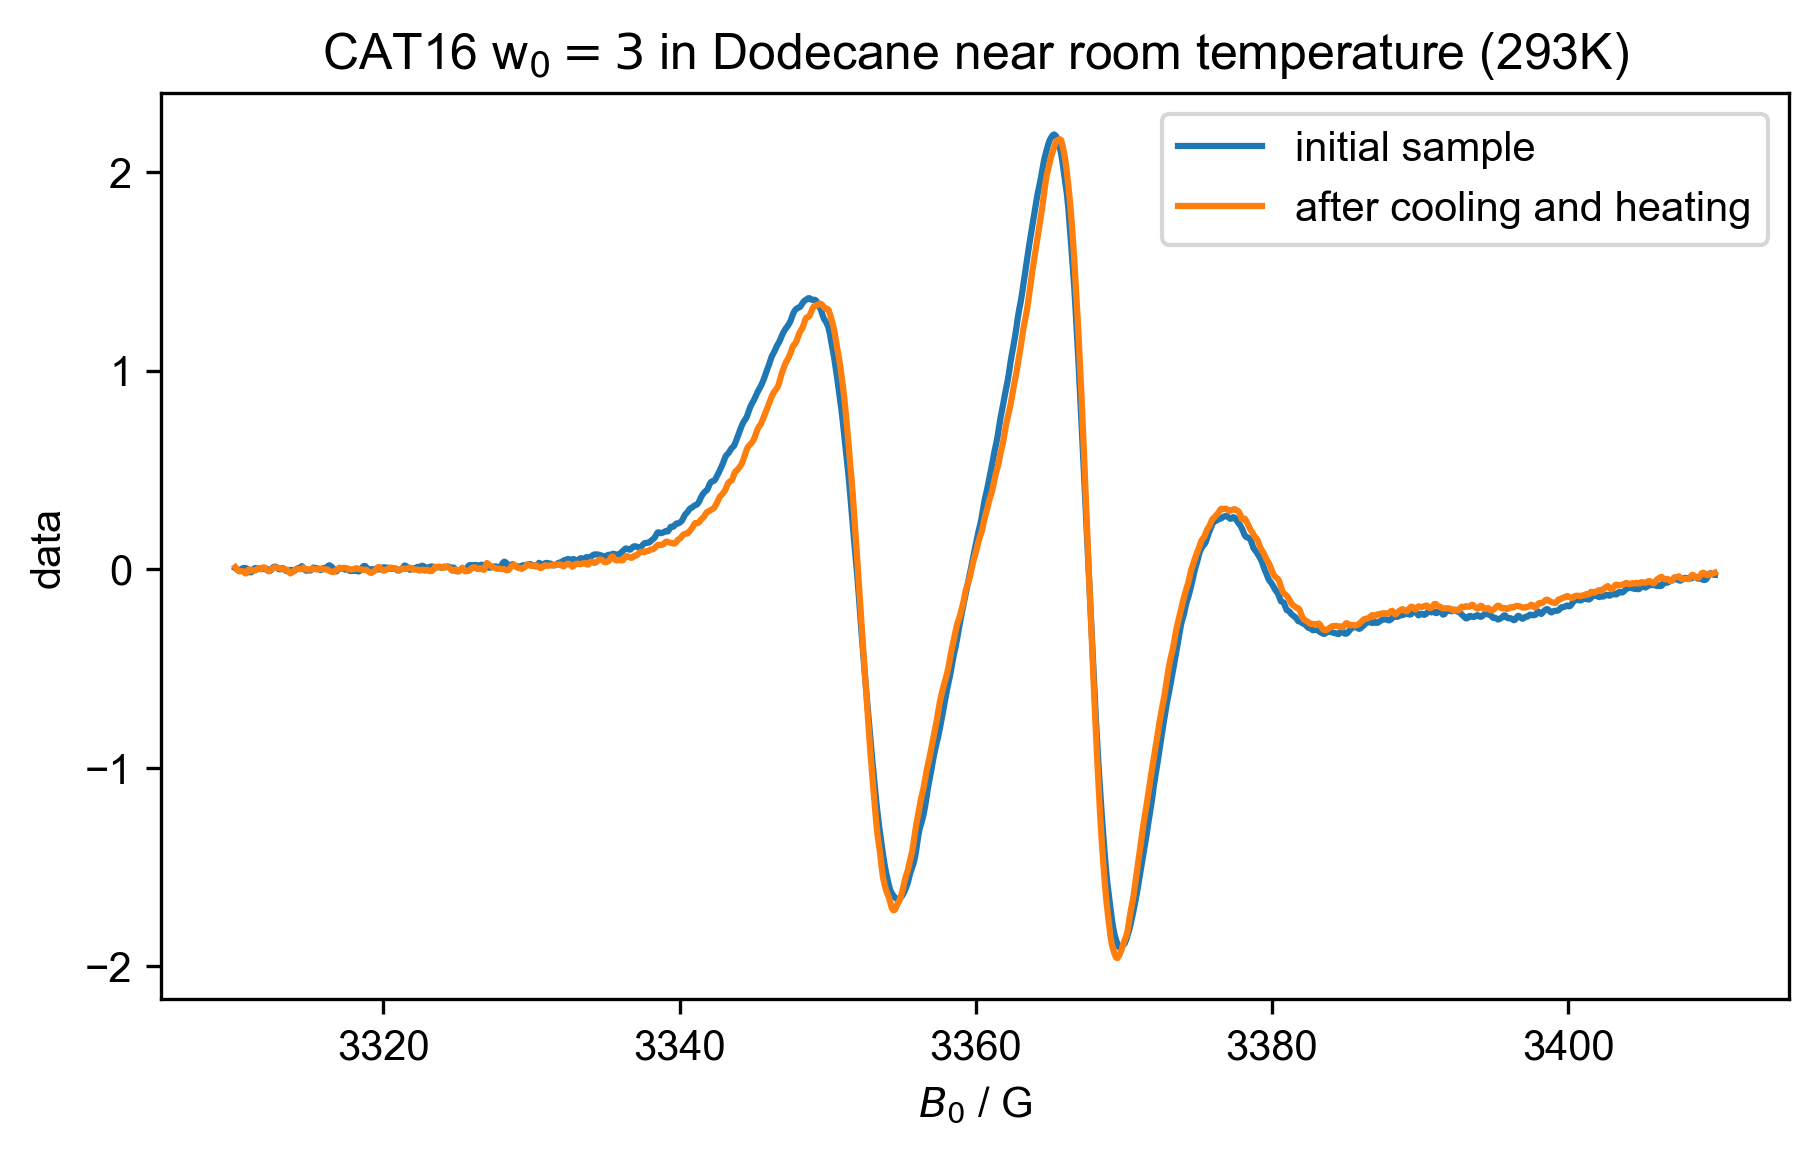

In [29]:
#near room temperature
# print(d2.getaxis("Temperature"))
figure(dpi=300, figsize=(7,4))
plot(d1["Temperature":293.628], label="initial sample")
plot(d2["Temperature":293.073], label="after cooling and heating")
title("CAT16 w$_0= 3$ in Dodecane near room temperature (293K)")
legend()

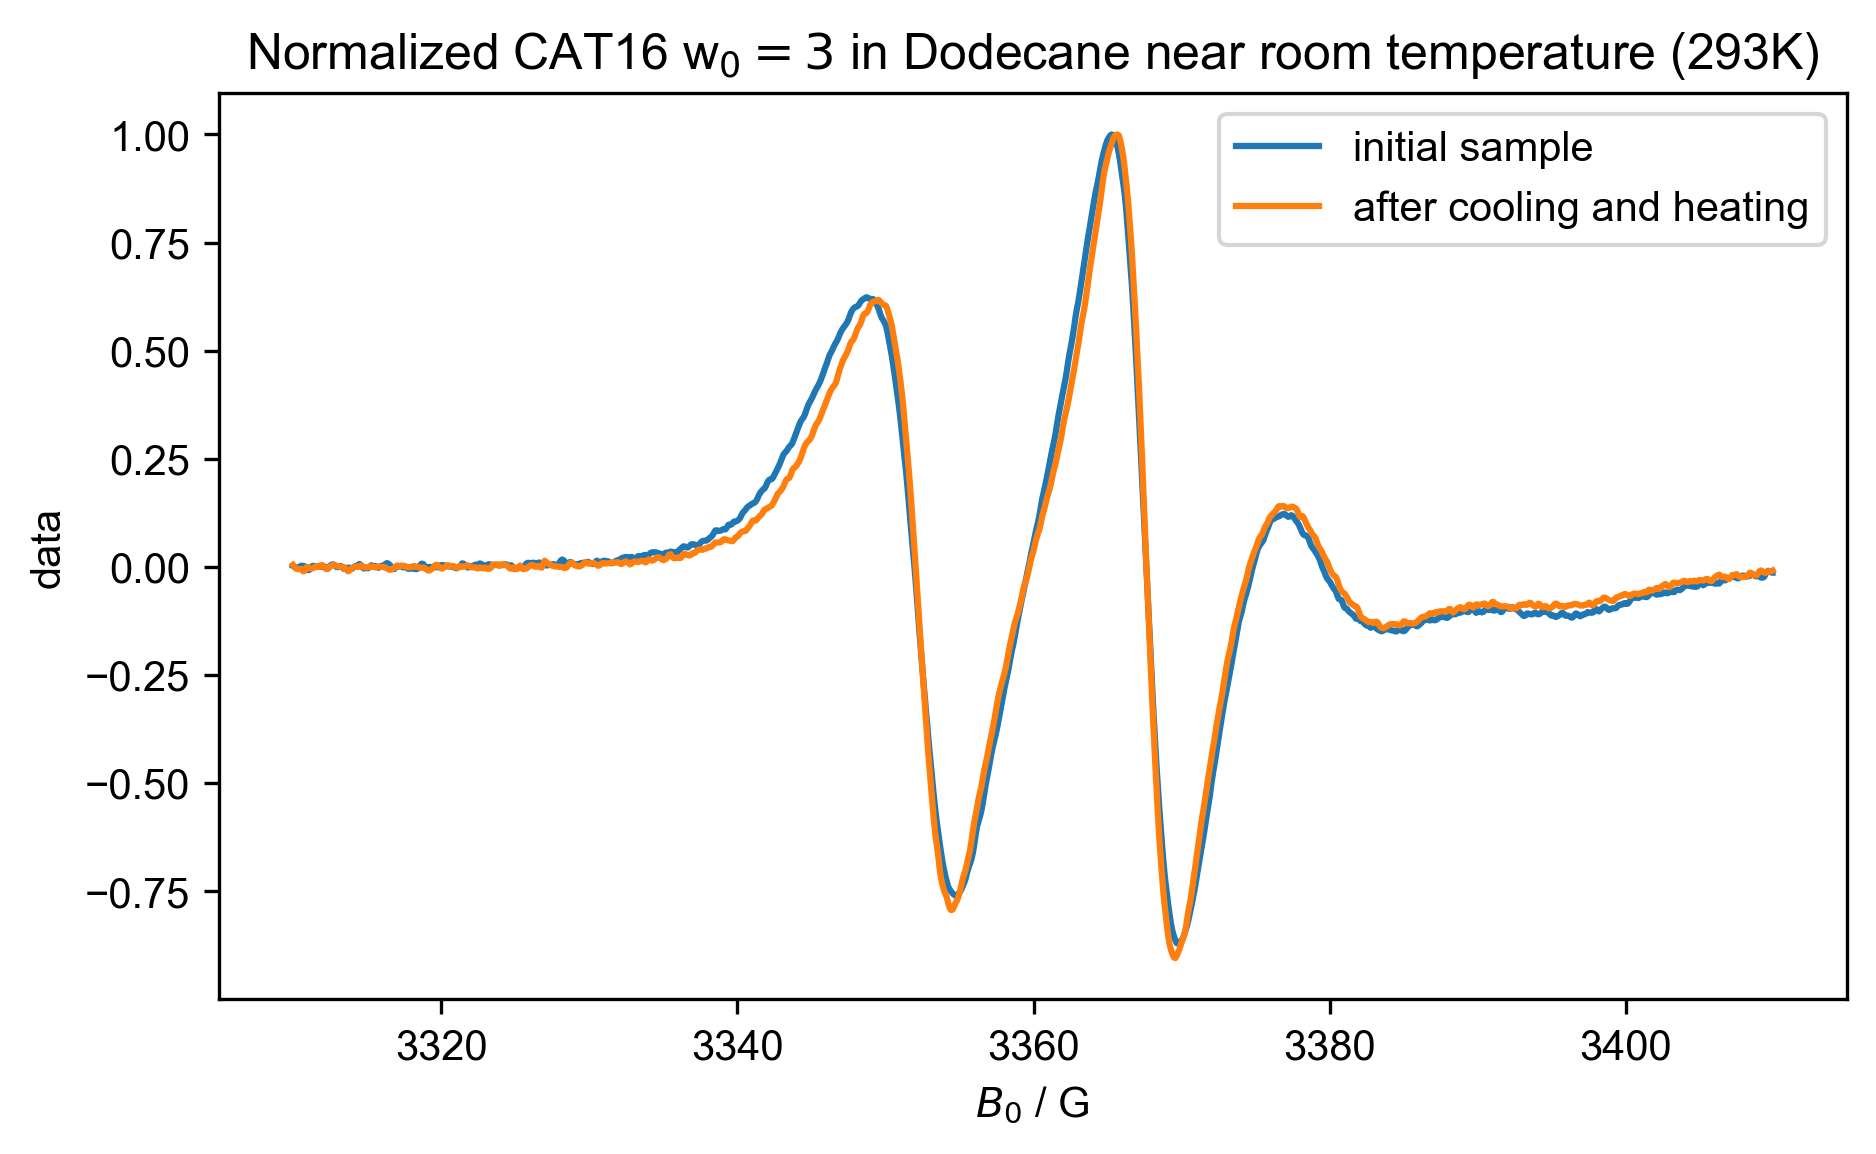

In [30]:
#Normalized
figure(dpi=300, figsize=(7,4))
plot(d1["Temperature": 293] / d1["Temperature": 293].max(), label= "initial sample")
plot(d2["Temperature": 293] / d2["Temperature": 293].max(), label= "after cooling and heating")
title("Normalized CAT16 w$_0= 3$ in Dodecane near room temperature (293K)")
legend()

## CAT16 w0= 20 

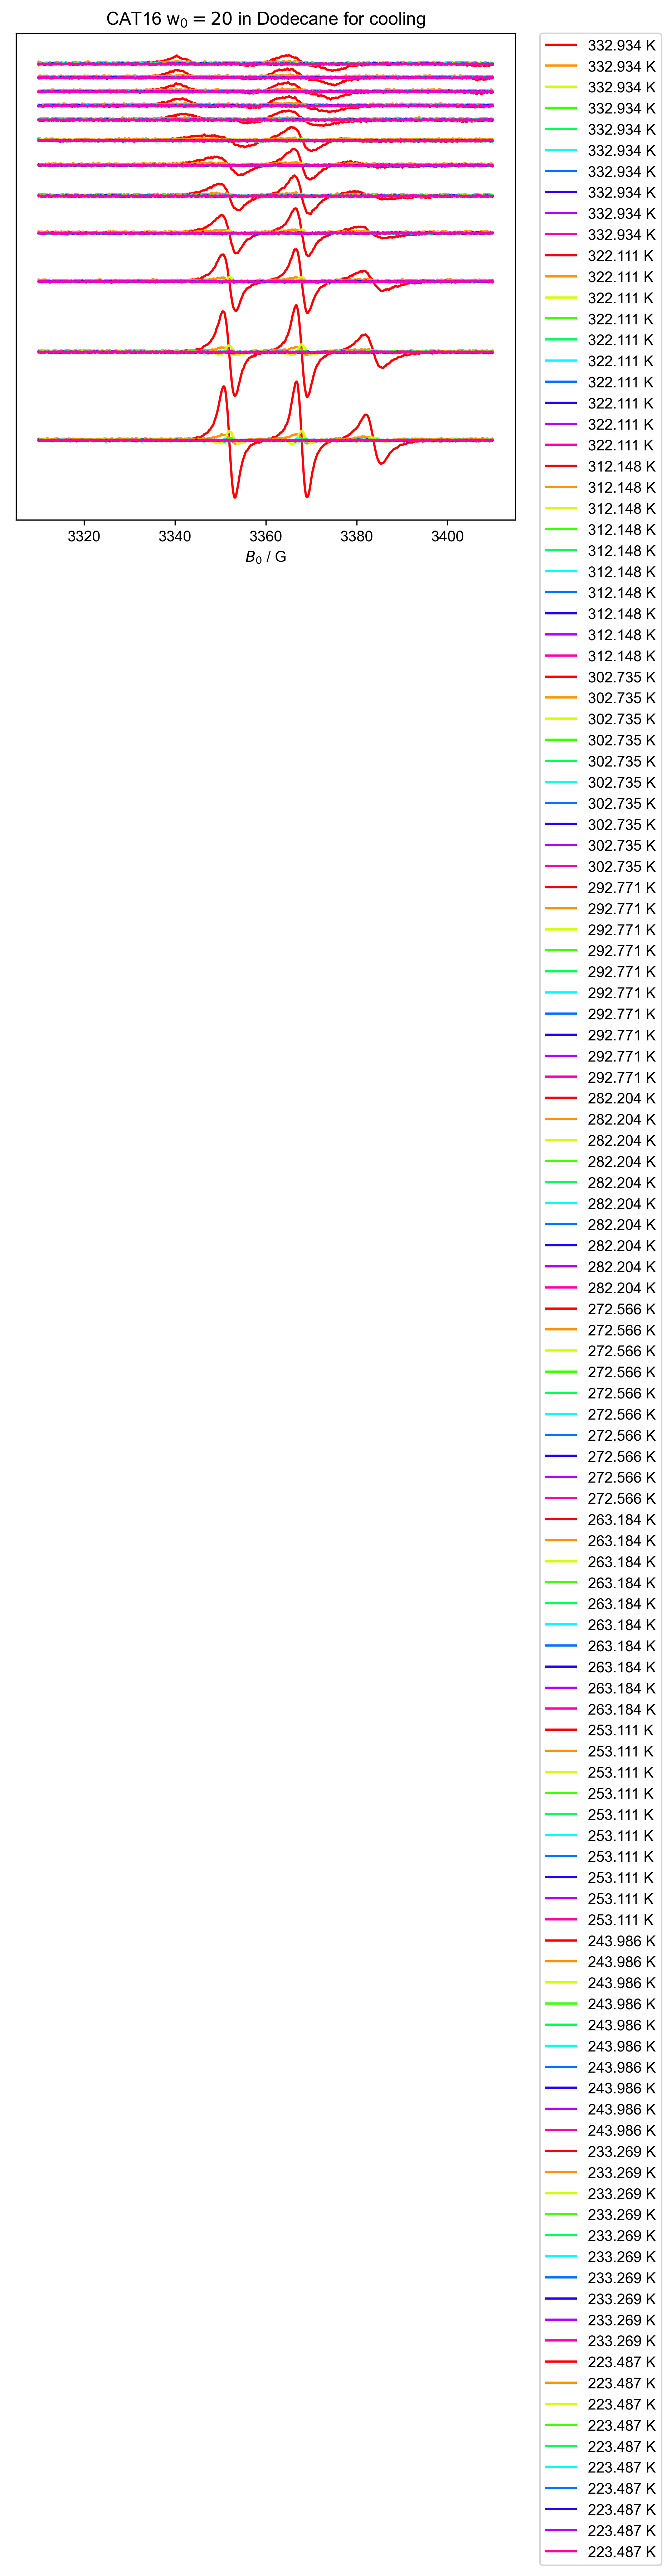

In [29]:
#cooling same plot in offset
offset= 0

for this_label, temp_range in [
    ("CAT16 w$_0= 20$ in Dodecane for cooling", (173, 373))
]:
    this_d3 = d3["Temperature":temp_range]
    figure(dpi=300, figsize=(6,6)) # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d3.shape["Temperature"]):
        this_temp = this_d3.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d3["Temperature", temp_ithis_dx] + offset, label=f"{this_temp} K")        
        offset += this_d3["Temperature", temp_ithis_dx].max()*1.5
        ax=plt.gca()
        ax.set_yticks([])
        ax.set_ylabel(None)
    fancy_legend()

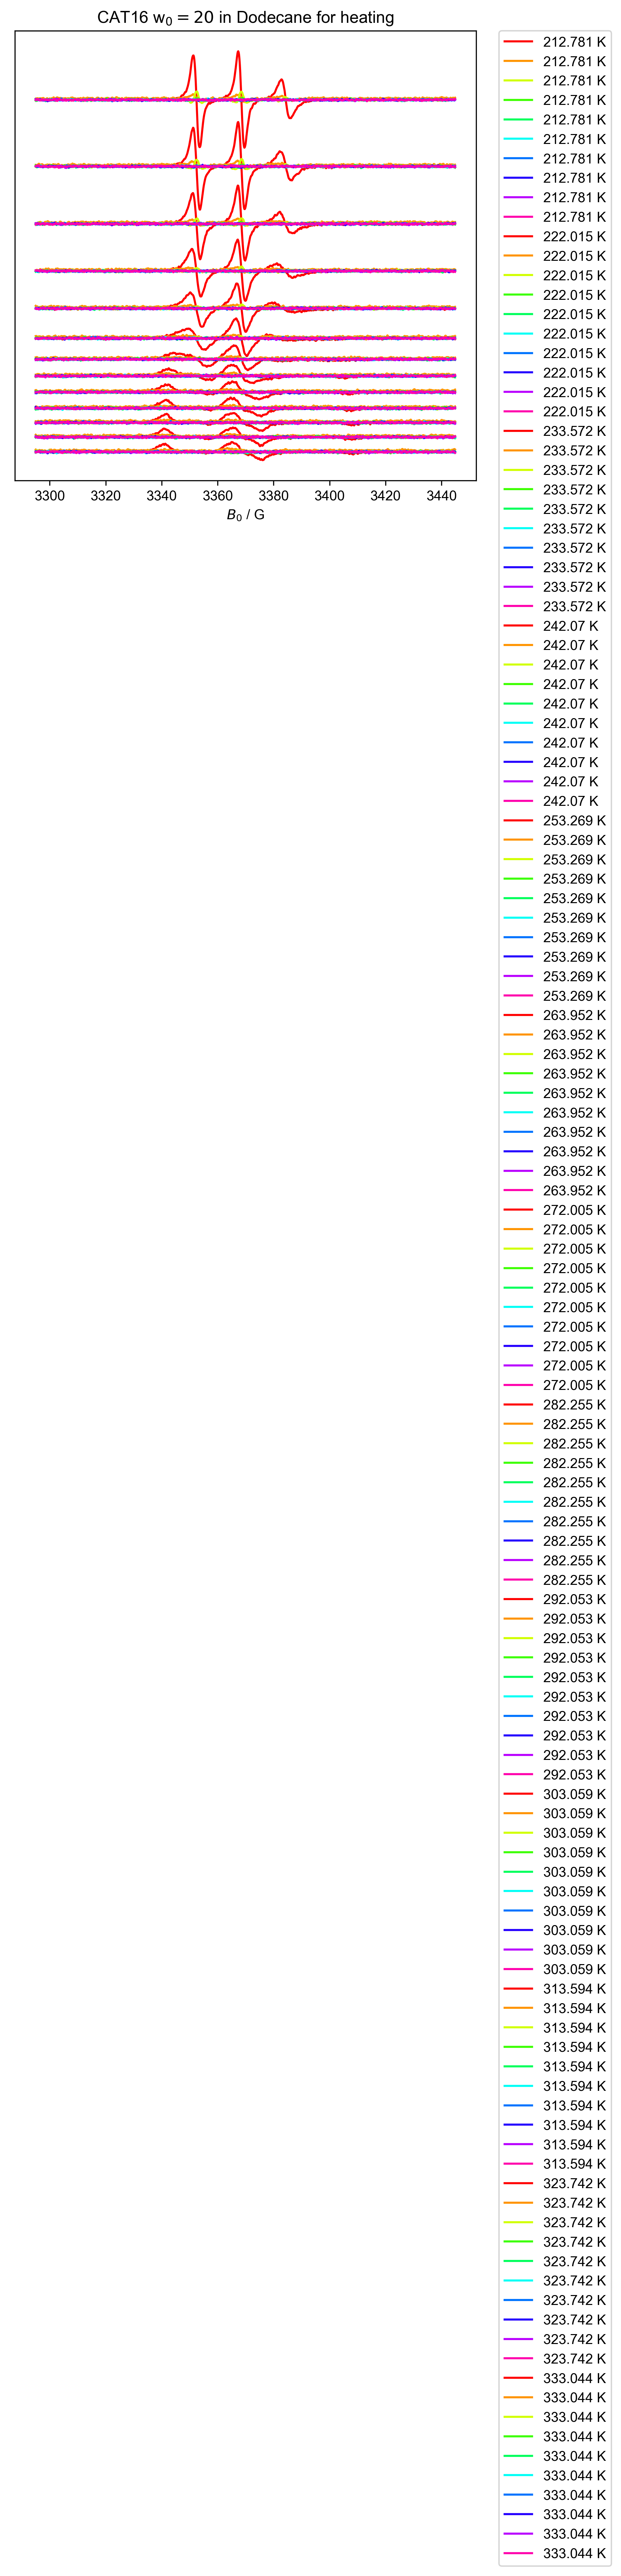

In [46]:
#heating run2 in same plot
offset =0

for this_label, temp_range in [
    ("CAT16 w$_0=20$ in Dodecane for heating", (173, 373)),
]:
    this_d4 = d4["Temperature":temp_range]
    figure(dpi=300, figsize=(6,6)) # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d4.shape["Temperature"]):
        this_temp = this_d4.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d4["Temperature", temp_ithis_dx] + offset, label=f"{this_temp} K")
        offset += this_d4["Temperature", temp_ithis_dx].max()*1.5
        ax=plt.gca()
        ax.set_yticks([])
        ax.set_ylabel(None)
    fancy_legend()

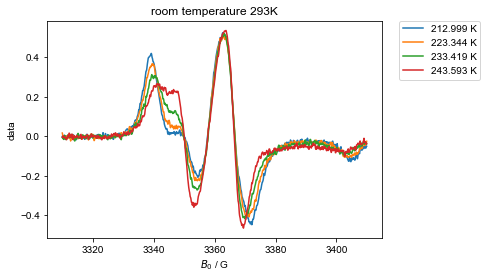

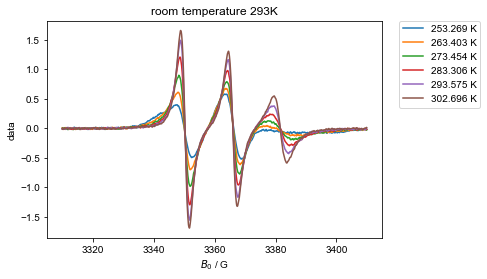

In [62]:
for this_label, temp_range in [
    ("below transition", (None, 247.8)),
    ("above transition", (248, None)),
]:
    this_d2 = d2["Temperature":temp_range]
    figure() # this is standard matplotlib to open a new figure
    title("room temperature 293K")
    for temp_ithis_dx in range(this_d2.shape["Temperature"]):
        this_temp = this_d2.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d2["Temperature", temp_ithis_dx], label=f"{this_temp} K")
    fancy_legend()

What if I wanted to pull the max and min to calculate the correlation time? How would I do that?

Start by slicing out the left peak -- note that the way I loaded pyspecdata at the top, inspecting an nddata just gives me a plot:

In [ ]:
d["Temperature":(258,None)]['$B_0$':(3340,3360)]

Here, I'm going to take the peak I just sliced, and determine its linewidth.  This is a simple example, but contains all the programming that I would need to, e.g. determine the correlation time or the hyperfine coupling using the traditional methods that look at the peak heights and linewidths:

In [ ]:
this_d = d["Temperature":(258,None)]['$B_0$':(3340,3360)]
default_color_cycle = cycle(rcParams['axes.prop_cycle'].by_key()['color'])
for j in range(this_d.shape["Temperature"]):
    c = next(default_color_cycle)
    plot(this_d['Temperature',j],alpha=0.5,c=c)
    field_at_max = this_d['Temperature',j].argmax().item()
    plot(field_at_max,this_d['Temperature',j]['$B_0$':field_at_max].item(),'x',c=c)
    field_at_min = this_d['Temperature',j].argmin()['$B_0$'] # it's a pyspecdata error that this isn't the same as argmax
    plot(field_at_min,this_d['Temperature',j]['$B_0$':field_at_min].item(),'x',c=c)
    print("the linewidth at",this_d['Temperature'][j],"K is",field_at_min-field_at_max,"G")
    print("the peak to peak amplitude at",this_d['Temperature'][j],"K is",(
        this_d['Temperature',j]['$B_0$':field_at_max].item()
        - this_d['Temperature',j]['$B_0$':field_at_min].item()))